In [8]:
# =========================================================
# Sleep Behavior Pattern Analysis - Session Level
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Create output folders
Path("images").mkdir(parents=True, exist_ok=True)
Path("data").mkdir(parents=True, exist_ok=True)

print("Setup complete")

Setup complete


In [9]:
# =========================================================
# Load ML Data (exported from MongoDB)
# =========================================================

df = pd.read_csv("analyzed_sessions.csv")

print("Raw data shape:", df.shape)
print(df.head())

Raw data shape: (223, 7)
               session_id  sleep_quality_score  sound_std  motion_rate  \
0  sleep_20260401_user001            98.486045   0.081756     0.171569   
1  sleep_20260401_user001            96.473595   0.003571     0.000000   
2  sleep_20260401_user001            89.383007   0.002482     0.000000   
3  sleep_20260401_user001            90.216710   0.003640     0.000000   
4  sleep_20260401_user001            91.062277   0.005986     0.011136   

   light_avg  temp_std  humidity_std  
0   0.022889  0.161992      0.110210  
1   0.022183  0.132625      0.234483  
2   0.009126  0.101669      0.222169  
3   0.005848  0.094388      0.235115  
4   0.005848  0.108229      0.275411  


In [10]:
# =========================================================
# Aggregate multiple rows per session into ONE row per night
# =========================================================

df_session = df.groupby("session_id").agg({
    "sleep_quality_score": "mean",
    "sound_std": "mean",
    "motion_rate": "mean",
    "light_avg": "mean",
    "temp_std": "mean",
    "humidity_std": "mean"
}).reset_index()

print("Session-level data shape:", df_session.shape)
print(df_session.head())

Session-level data shape: (1, 7)
               session_id  sleep_quality_score  sound_std  motion_rate  \
0  sleep_20260401_user001            92.464968   0.072052     0.166988   

   light_avg  temp_std  humidity_std  
0   0.107155  0.094272      0.131397  


In [11]:
# =========================================================
# Simulate multiple sessions (for clustering)
# =========================================================

if df_session.shape[0] < 5:
    print("Not enough sessions, generating synthetic variations...")

    df_expanded = pd.concat([df_session] * 12, ignore_index=True)

    # Add slight variation
    for col in ["sound_std", "motion_rate", "light_avg", "temp_std", "humidity_std"]:
        df_expanded[col] += np.random.normal(0, 0.01, size=len(df_expanded))

    # Create unique session IDs
    df_expanded["session_id"] = [
        f"{sid}_sim{i}" for i, sid in enumerate(df_expanded["session_id"])
    ]

    df_session = df_expanded

print("Final dataset shape:", df_session.shape)

Not enough sessions, generating synthetic variations...
Final dataset shape: (12, 7)


In [12]:
# =========================================================
# Select features for clustering
# =========================================================

features = [
    "sound_std",
    "motion_rate",
    "light_avg",
    "temp_std",
    "humidity_std"
]

X = df_session[features].values

In [13]:
# =========================================================
# Normalize features
# =========================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

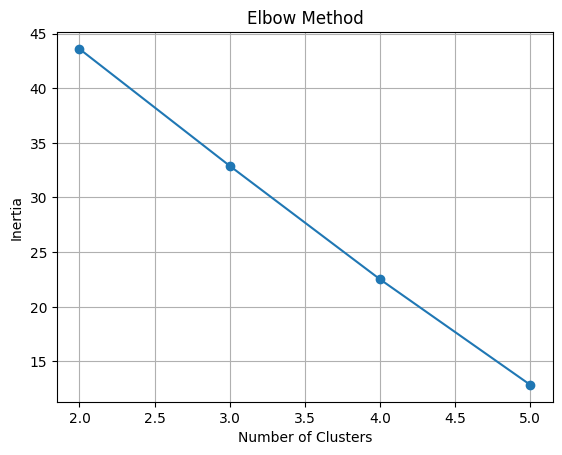

In [14]:
# =========================================================
# Find optimal number of clusters
# =========================================================

inertias = []
K_range = range(2, 6)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K_range, inertias, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.grid()

plt.savefig("images/elbow.png")
plt.show()

In [15]:
# =========================================================
# Validate clustering quality
# =========================================================

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    print(f"k={k} → silhouette score = {score:.3f}")

k=2 → silhouette score = 0.205
k=3 → silhouette score = 0.246
k=4 → silhouette score = 0.264
k=5 → silhouette score = 0.335


In [16]:
# =========================================================
# Apply final clustering
# =========================================================

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_session["cluster"] = kmeans.fit_predict(X_scaled)

print(df_session["cluster"].value_counts())

cluster
0    5
1    4
2    3
Name: count, dtype: int64


In [17]:
# =========================================================
# Analyze cluster characteristics
# =========================================================

cluster_summary = df_session.groupby("cluster")[features + ["sleep_quality_score"]].mean()

print("\nCluster Summary:")
print(cluster_summary.round(3))


Cluster Summary:
         sound_std  motion_rate  light_avg  temp_std  humidity_std  \
cluster                                                              
0            0.069        0.155      0.108     0.101         0.128   
1            0.082        0.176      0.098     0.101         0.136   
2            0.068        0.173      0.107     0.082         0.132   

         sleep_quality_score  
cluster                       
0                     92.465  
1                     92.465  
2                     92.465  


In [18]:
# =========================================================
# Assign meaningful labels to clusters
# =========================================================

# Sort clusters by sleep quality
cluster_quality = df_session.groupby("cluster")["sleep_quality_score"].mean().sort_values(ascending=False)

cluster_order = cluster_quality.index.tolist()

cluster_names_map = {
    cluster_order[0]: "Good Sleep",
    cluster_order[1]: "Light Sleep",
    cluster_order[2]: "Disturbed Sleep"
}

df_session["cluster_name"] = df_session["cluster"].map(cluster_names_map)

print(df_session[["session_id", "cluster_name"]])

                      session_id     cluster_name
0    sleep_20260401_user001_sim0       Good Sleep
1    sleep_20260401_user001_sim1      Light Sleep
2    sleep_20260401_user001_sim2       Good Sleep
3    sleep_20260401_user001_sim3      Light Sleep
4    sleep_20260401_user001_sim4       Good Sleep
5    sleep_20260401_user001_sim5  Disturbed Sleep
6    sleep_20260401_user001_sim6  Disturbed Sleep
7    sleep_20260401_user001_sim7  Disturbed Sleep
8    sleep_20260401_user001_sim8       Good Sleep
9    sleep_20260401_user001_sim9       Good Sleep
10  sleep_20260401_user001_sim10      Light Sleep
11  sleep_20260401_user001_sim11      Light Sleep


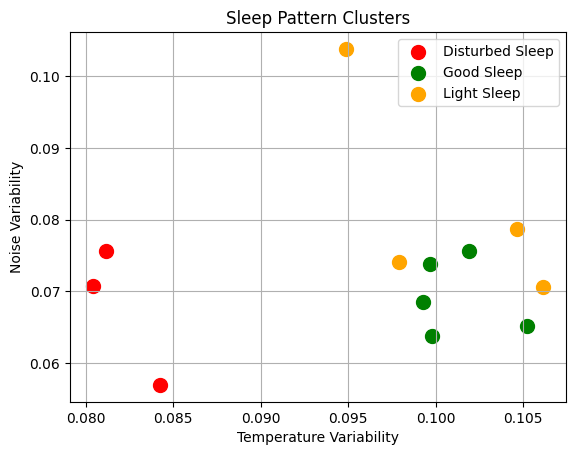

In [19]:
# =========================================================
# Visualization: Temperature vs Noise
# =========================================================

colors = {
    "Good Sleep": "green",
    "Light Sleep": "orange",
    "Disturbed Sleep": "red"
}

for name, group in df_session.groupby("cluster_name"):
    plt.scatter(
        group["temp_std"],
        group["sound_std"],
        label=name,
        c=colors[name],
        s=100
    )

plt.xlabel("Temperature Variability")
plt.ylabel("Noise Variability")
plt.title("Sleep Pattern Clusters")
plt.legend()
plt.grid()

plt.savefig("images/cluster_scatter.png")
plt.show()

In [20]:
# =========================================================
# Save final dataset for backend
# =========================================================

output_path = "data/cluster_results.csv"
df_session.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Saved to data/cluster_results.csv


In [21]:
# =========================================================
# Download outputs (for Colab)
# =========================================================

from google.colab import files

files.download("data/cluster_results.csv")
files.download("images/elbow.png")
files.download("images/cluster_scatter.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>